# On time modelling in TEM
We would like to model the magnetic field during the excitations pulses. It seems this is no issue based on the mathmetical formulation using the Fourier transform (inverse Fourier) to go from frequency to time domain. However, the Hankel based Fourier transform formulation seems to have a positivity constraint in the evaluation of times. I gather the same is true for the inverse laplace. Let's look at the problem.

In [1]:
from anemone.forwards import Forward
from anemone.experiment import *
import matplotlib.pyplot as plt
import numpy as np

In [2]:
tx = Loop.square(40)
rx = Receiver()
t = torch.logspace(torch.log10(torch.tensor(1.1e-6)), -3, 35)
wv = Waveform.example()

In [3]:
t0 = wv.time.min()
wv.time = wv.time - t0

fwr = Forward(tx, rx, t-t0, waveform=wv)

/home/matt/repositories/anemone/src/anemone/experiment/experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [4]:
rho = torch.tensor([30., 50., 20.])*0.1
thk = torch.tensor([30., 30.])

dbdt = fwr(rho, thk)

hankel coefficients didnt converge
hankel coefficients didnt converge
hankel coefficients didnt converge
hankel coefficients didnt converge


/home/matt/repositories/anemone/src/anemone/experiment/experiment.py:274: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3683.)
  return HR.T.squeeze()


In [5]:
dbdt

tensor([       nan,        nan,        nan,        nan,        nan, 2.3082e-03,
        1.2864e-03, 8.2989e-04, 5.6866e-04, 4.0254e-04, 2.9064e-04, 2.1253e-04,
        1.5671e-04, 1.1618e-04, 8.6420e-05, 6.4399e-05, 4.8015e-05, 3.5783e-05,
        2.6631e-05, 1.9778e-05, 1.4646e-05, 1.0806e-05, 7.9373e-06, 5.7998e-06,
        4.2120e-06, 3.0371e-06, 2.1719e-06, 1.5385e-06, 1.0779e-06, 7.4580e-07,
        5.0855e-07, 3.4102e-07, 2.2427e-07, 1.8274e-07, 1.0310e-07],
       dtype=torch.float64)

so gates in the down ramp are not working...
let's look at the evaluation times for the B-field step off:

In [6]:
t_eval = fwr.times[:, None] - fwr.waveform.time[None, :]
print(t_eval)

tensor([[ 1.0537e-03,  9.3073e-04,  1.1000e-06, -1.4000e-06],
        [ 1.0539e-03,  9.3097e-04,  1.3440e-06, -1.1560e-06],
        [ 1.0542e-03,  9.3127e-04,  1.6421e-06, -8.5786e-07],
        [ 1.0546e-03,  9.3164e-04,  2.0065e-06, -4.9348e-07],
        [ 1.0551e-03,  9.3208e-04,  2.4517e-06, -4.8311e-08],
        [ 1.0556e-03,  9.3263e-04,  2.9956e-06,  4.9558e-07],
        [ 1.0563e-03,  9.3329e-04,  3.6602e-06,  1.1602e-06],
        [ 1.0571e-03,  9.3410e-04,  4.4722e-06,  1.9722e-06],
        [ 1.0581e-03,  9.3509e-04,  5.4643e-06,  2.9643e-06],
        [ 1.0593e-03,  9.3631e-04,  6.6765e-06,  4.1765e-06],
        [ 1.0608e-03,  9.3779e-04,  8.1578e-06,  5.6578e-06],
        [ 1.0626e-03,  9.3960e-04,  9.9676e-06,  7.4676e-06],
        [ 1.0648e-03,  9.4181e-04,  1.2179e-05,  9.6789e-06],
        [ 1.0675e-03,  9.4451e-04,  1.4881e-05,  1.2381e-05],
        [ 1.0708e-03,  9.4781e-04,  1.8182e-05,  1.5682e-05],
        [ 1.0748e-03,  9.5185e-04,  2.2216e-05,  1.9716e-05],
        

The first 5 gates contain times before the ramp down (i.e. negative times). These are causing the problem I gather.
However, I suspect there is symmetry (or antisymmetry) in the B-field step response that can be exploited to compute the solution at these times.
The b-field response to a Horizontal electric dipole is:

$$ H_z = \frac{I ds}{4 \pi}\frac{y}{\rho} \int_0^{\infty} (1 + r_{TE}) e^{u_0 z} \frac{\lambda^2}{u_0} J_1 (\lambda \rho) d\lambda $$

this is for a transmitter on the surface...

$$ H_z = \frac{I ds}{4 \pi}\frac{y}{\rho} \int_0^{\infty} (1 + r_{TE}) e^{u_0 z} \frac{\lambda^2}{u_0} J_1 (\lambda \rho) d\lambda $$


## Symmetry of the dipole response solution
### symmetry of $r_{TE}$
lets first look at the symmetry in $r_{TE}$.

Text(0, 0.5, '$\\lambda$ [m]')

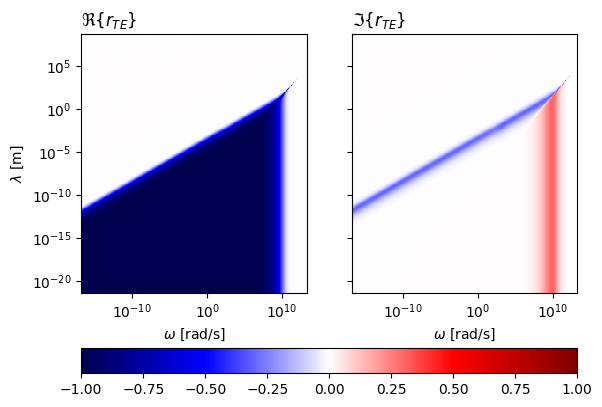

In [7]:
from anemone.physics import refl_transverse_electric
rte = refl_transverse_electric(fwr.sigma, fwr.thick, fwr.omega, fwr.lamda).squeeze().T
fig, ax = plt.subplots(1,2, sharex=True, sharey=True)
ax[0].pcolor(torch.log10(fwr.omega.squeeze()), torch.log10(fwr.lamda.squeeze()), rte.real, vmin=-1, vmax=1, cmap='seismic')
pcm=ax[1].pcolor(torch.log10(fwr.omega.squeeze()), torch.log10(fwr.lamda.squeeze()), rte.imag, vmin=-1, vmax=1, cmap='seismic')
fig.colorbar(pcm, ax=ax, orientation='horizontal')
ax[0].set_title('$\\Re\\{r_{TE}\\}$', loc='left')
ax[1].set_title('$\\Im\\{r_{TE}\\}$', loc='left')
ax[0].xaxis.set_major_formatter('10$^{{{x:0.0f}}}$')
ax[0].yaxis.set_major_formatter('10$^{{{x:0.0f}}}$')
ax[0].set_xlabel('$\\omega$ [rad/s]'); ax[1].set_xlabel('$\\omega$ [rad/s]')
ax[0].set_ylabel('$\\lambda$ [m]')

Text(0, 0.5, '$\\lambda$ [m]')

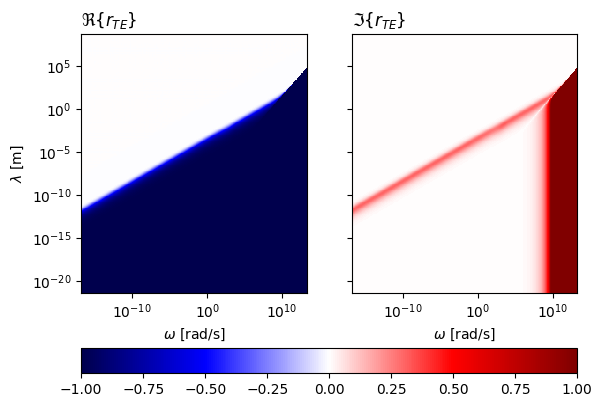

In [8]:
from anemone.physics import refl_transverse_electric
rte = refl_transverse_electric(fwr.sigma, fwr.thick, -fwr.omega, fwr.lamda).squeeze().T
fig, ax = plt.subplots(1,2, sharex=True, sharey=True)
ax[0].pcolor(torch.log10(fwr.omega.squeeze()), torch.log10(fwr.lamda.squeeze()), rte.real, vmin=-1, vmax=1, cmap='seismic')
pcm=ax[1].pcolor(torch.log10(fwr.omega.squeeze()), torch.log10(fwr.lamda.squeeze()), rte.imag, vmin=-1, vmax=1, cmap='seismic')
fig.colorbar(pcm, ax=ax, orientation='horizontal')
ax[0].set_title('$\\Re\\{r_{TE}\\}$', loc='left')
ax[1].set_title('$\\Im\\{r_{TE}\\}$', loc='left')
ax[0].xaxis.set_major_formatter('10$^{{{x:0.0f}}}$')
ax[0].yaxis.set_major_formatter('10$^{{{x:0.0f}}}$')
ax[0].set_xlabel('$\\omega$ [rad/s]'); ax[1].set_xlabel('$\\omega$ [rad/s]')
ax[0].set_ylabel('$\\lambda$ [m]')

my guess is that the rte is symmetric in the real component and anti-symmetric in the imaginary component. I don't really believe the edge above a frequency of -10^10 Hz
especially since the absolute value of the reflection coefficient would be greater than one for that edge.

### symmetry of $u_o$

Text(0, 0.5, '$\\lambda$ [m]')

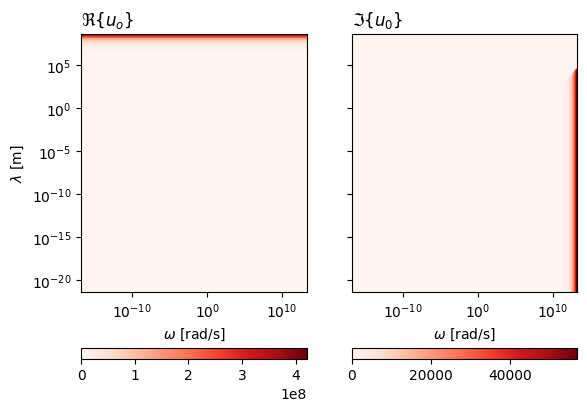

In [9]:
from anemone.physics import freespace_u0
u0 = freespace_u0(fwr.omega, fwr.lamda).squeeze().T
fig, ax = plt.subplots(1,2, sharex=True, sharey=True)
pcm = ax[0].pcolor(torch.log10(fwr.omega.squeeze()), torch.log10(fwr.lamda.squeeze()), u0.real,  cmap='Reds')
fig.colorbar(pcm, ax=ax[0], orientation='horizontal')
pcm = ax[1].pcolor(torch.log10(fwr.omega.squeeze()), torch.log10(fwr.lamda.squeeze()), u0.imag,  cmap='Reds')
fig.colorbar(pcm, ax=ax[1], orientation='horizontal')
ax[0].set_title('$\\Re\\{u_o\\}$', loc='left')
ax[1].set_title('$\\Im\\{u_0\\}$', loc='left')
ax[0].xaxis.set_major_formatter('10$^{{{x:0.0f}}}$')
ax[0].yaxis.set_major_formatter('10$^{{{x:0.0f}}}$')
ax[0].set_xlabel('$\\omega$ [rad/s]'); ax[1].set_xlabel('$\\omega$ [rad/s]')
ax[0].set_ylabel('$\\lambda$ [m]')

Text(0, 0.5, '$\\lambda$ [m]')

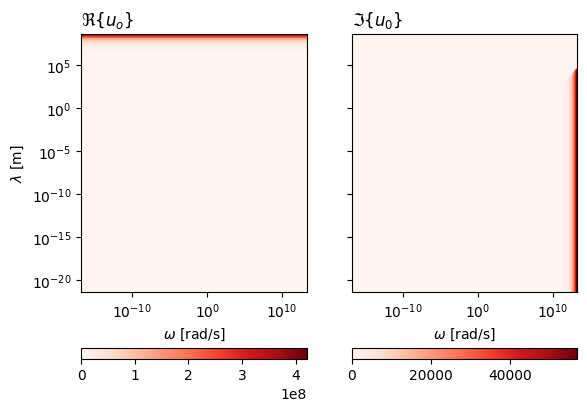

In [10]:
from anemone.physics import freespace_u0
u0 = freespace_u0(-fwr.omega, fwr.lamda).squeeze().T
fig, ax = plt.subplots(1,2, sharex=True, sharey=True)
pcm = ax[0].pcolor(torch.log10(fwr.omega.squeeze()), torch.log10(fwr.lamda.squeeze()), u0.real, cmap='Reds')
fig.colorbar(pcm, ax=ax[0], orientation='horizontal')
pcm = ax[1].pcolor(torch.log10(fwr.omega.squeeze()), torch.log10(fwr.lamda.squeeze()), u0.imag, cmap='Reds')
fig.colorbar(pcm, ax=ax[1], orientation='horizontal')
ax[0].set_title('$\\Re\\{u_o\\}$', loc='left')
ax[1].set_title('$\\Im\\{u_0\\}$', loc='left')
ax[0].xaxis.set_major_formatter('10$^{{{x:0.0f}}}$')
ax[0].yaxis.set_major_formatter('10$^{{{x:0.0f}}}$')
ax[0].set_xlabel('$\\omega$ [rad/s]'); ax[1].set_xlabel('$\\omega$ [rad/s]')
ax[0].set_ylabel('$\\lambda$ [m]')

Excellent! symmetric in both real and imaginary.

### symmetry of $e^{-u_o z}$
just for sanity


Text(0, 0.5, '$\\lambda$ [m]')

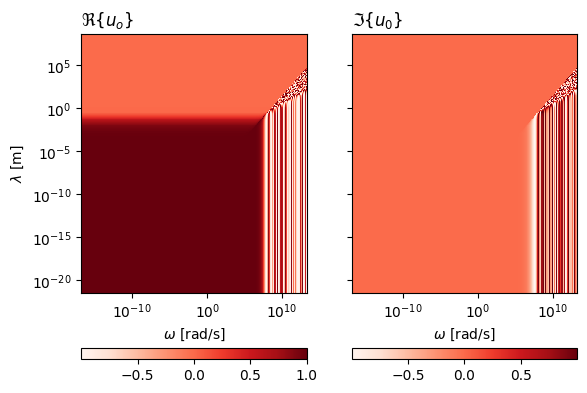

In [11]:
from anemone.physics import freespace_u0
u0 = freespace_u0(fwr.omega, fwr.lamda).squeeze().T
z = 10.
u0 = torch.exp(-u0*z)

fig, ax = plt.subplots(1,2, sharex=True, sharey=True)
pcm = ax[0].pcolor(torch.log10(fwr.omega.squeeze()), torch.log10(fwr.lamda.squeeze()), u0.real,  cmap='Reds')
fig.colorbar(pcm, ax=ax[0], orientation='horizontal')
pcm = ax[1].pcolor(torch.log10(fwr.omega.squeeze()), torch.log10(fwr.lamda.squeeze()), u0.imag,  cmap='Reds')
fig.colorbar(pcm, ax=ax[1], orientation='horizontal')
ax[0].set_title('$\\Re\\{u_o\\}$', loc='left')
ax[1].set_title('$\\Im\\{u_0\\}$', loc='left')
ax[0].xaxis.set_major_formatter('10$^{{{x:0.0f}}}$')
ax[0].yaxis.set_major_formatter('10$^{{{x:0.0f}}}$')
ax[0].set_xlabel('$\\omega$ [rad/s]'); ax[1].set_xlabel('$\\omega$ [rad/s]')
ax[0].set_ylabel('$\\lambda$ [m]')

Text(0, 0.5, '$\\lambda$ [m]')

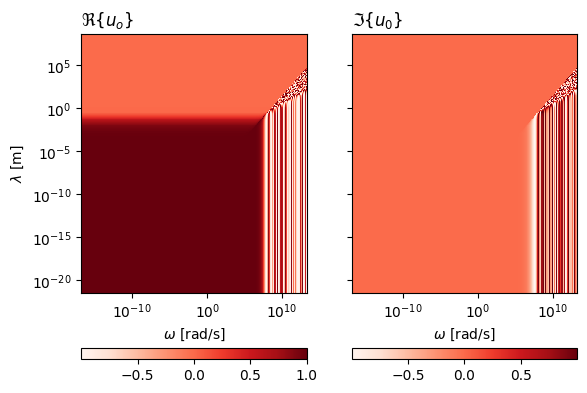

In [12]:
from anemone.physics import freespace_u0
u0 = freespace_u0(-fwr.omega, fwr.lamda).squeeze().T
z = 10.
u0 = torch.exp(-u0*z)

fig, ax = plt.subplots(1,2, sharex=True, sharey=True)
pcm = ax[0].pcolor(torch.log10(fwr.omega.squeeze()), torch.log10(fwr.lamda.squeeze()), u0.real,  cmap='Reds')
fig.colorbar(pcm, ax=ax[0], orientation='horizontal')
pcm = ax[1].pcolor(torch.log10(fwr.omega.squeeze()), torch.log10(fwr.lamda.squeeze()), u0.imag,  cmap='Reds')
fig.colorbar(pcm, ax=ax[1], orientation='horizontal')
ax[0].set_title('$\\Re\\{u_o\\}$', loc='left')
ax[1].set_title('$\\Im\\{u_0\\}$', loc='left')
ax[0].xaxis.set_major_formatter('10$^{{{x:0.0f}}}$')
ax[0].yaxis.set_major_formatter('10$^{{{x:0.0f}}}$')
ax[0].set_xlabel('$\\omega$ [rad/s]'); ax[1].set_xlabel('$\\omega$ [rad/s]')
ax[0].set_ylabel('$\\lambda$ [m]')

kind of stupid. anyways...

this is great news. looking at the terms in the dipole expression we have:
$$\underbrace{(1 + r_{TE})}_{+\\Re, -\\Im} \underbrace{e^{u_0 z}\frac{\lambda^2}{u_0}}_{sym}$$
ok. then for the step reponse, we divide everything by $i\omega$, which is of course anti-symmetric, and swaps the real and imaginary components.

In [13]:
from anemone.transforms import Hankel, invFourier, CubicSpline

class Sine(invFourier):
    def __init__(self, func, log10min=-20, log10max=10, smp_per_decade=20, device=None, range=None):
        super().__init__(func, log10min, log10max, smp_per_decade, device, None)
        self.fc = self.fc.imag

    def __call__(self, r):
        if isinstance(r, float): r = torch.tensor(r, device=self.device)
        rmax = torch.abs(r).max()
        rmin = torch.abs(r).min()
        if not 'interpfunc' in dir(self):
            self.r, self.resp = self.range(rmin, rmax)
            self.interpfunc = CubicSpline(self.r, self.resp, integrate=False, transform=torch.log10)
        r = r if isinstance(r, torch.Tensor) else torch.tensor(r, device=self.device)

        return self.interpfunc(torch.abs(r))*torch.sign(r)

class Cosine(invFourier):
    def __init__(self, func, log10min=-20, log10max=10, smp_per_decade=20, device=None, range=None):
        super().__init__(func, log10min, log10max, smp_per_decade, device, None)
        self.fc = self.fc.real

    def __call__(self, r):
        if isinstance(r, float): r = torch.tensor(r, device=self.device)
        rmax = torch.abs(r).max()
        rmin = torch.abs(r).min()
        if not 'interpfunc' in dir(self):
            self.r, self.resp = self.range(rmin, rmax)
            self.interpfunc = CubicSpline(self.r, self.resp, integrate=False, transform=torch.log10)
        r = r if isinstance(r, torch.Tensor) else torch.tensor(r, device=self.device)
        return self.interpfunc(torch.abs(r))

In [ ]:
from anemone.physics import freespace_u0
class Forward2(Forward):
    omega = None
    lmb   = None
    geomz = None
    t2t   = None
    u0    = None
    sfield_rte = None
    pfield     = None

    def __init__(self, source, receiver, times, waveform, filterfunc=None, t_gatewidth=None, tolerance=None):
        super().__init__(source, receiver, times, waveform, filterfunc, t_gatewidth, tolerance)
    
    def calc_ft(self):
        def frq_integrand(f):
            self.omega = c.twopi*f[None,:,None]
            def wvlngth_integrand(wave_length):
                if self.lmb is None: self.lmb = wave_length[None, None, :]                
                if self.u0     is None: self.u0     = freespace_u0(self.omega, self.lmb)
                if self.sfield_rte is None: self.sfield_rte = torch.exp(-self.u0*self.sfield_dz) / self.u0
                if self.pfield     is None: self.pfield     = torch.exp(-self.u0*self.pfield_dz) / self.u0
                self.rte = refl_transverse_electric(self.sigma, self.thick, self.omega, self.lmb)

                intg = self.pfield + self.sfield_rte * self.rte

                return intg*self.lmb**2/c.fourpi
            
            
            if self.geomz is None:
                hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, smp_per_decade=10)
                def geomz_r(r):
                    return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
                res, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax, tolerance=1e-8)           
                self.sfield_rte = None
                self.pfield     = None
                self.u0         = None 
            else:
                res = torch.einsum('...i,i->...', wvlngth_integrand(self.lmb), self.geomz)
            return res / (-1j*self.omega.squeeze())
        return invFourier(frq_integrand, smp_per_decade=16, range=(self.tmin, self.tmax), device=self.device)

    def forward(self):
        self._ft = self.calc_ft()

        if self.t_gatewidth is None:
            t = self.times

        t_eval = t[:, None] - self.waveform.time[None, :]
        resp_step = self._ft(t_eval).real
        dbdt = resp_step @ self.waveform.d2wdt2
        return dbdt

In [22]:
from anemone.forwards import ForwardLaplace
from anemone.transforms import invLaplace

from anemone.experiment import lamontagne

def wv_to_t(t_eval, t_sampled, waveform=None):
    t_eval = t_eval.to(torch.double)
    t_sampled = t_sampled.to(torch.double)

    logT = torch.log(t_sampled)#.cpu()
    dT = logT[1]-logT[0]
    if waveform is None:
        t2t = lamontagne((torch.log(t_eval)[:,None]-logT[None,:])/dT)
    else:
        t2t = torch.zeros(t_eval.shape+t_sampled.shape, device=t_sampled.device, dtype=t_eval.dtype)

        for t_wv,k_wv in zip(waveform.time, waveform.d2wdt2):
            t2t += k_wv*lamontagne((torch.log(t_eval-t_wv)[:,None]-logT[None,:])/dT)
    return t2t


class ForwardLaplace6(ForwardLaplace):
    geomz = None
    t2t   = None
    

    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_gatewidth=None, tolerance=None, t_smp_per_decade=12):
        super().__init__(source, receiver, times, waveform, filterfunc, t_gatewidth, tolerance, t_smp_per_decade)
        self.t2t = wv_to_t(self.times, self.t_eval, waveform=self.waveform)#.to_sparse()

    def forward(self):
        def wvlngth_integrand(wave_length):
            self.lmb = wave_length[None, :, None]
            def s_integrand(s):
                """ Hz from horizontal electric dipole. """
                self.omega = -1j*s[None, None, :]
                
                self.tmp_u0 = freespace_u0(self.omega, self.lmb)
                self.sfield_rte = torch.exp(-self.tmp_u0*self.sfield_dz)#*self.lmb**2 / 
                intg = refl_transverse_electric(self.sigma, self.thick, self.omega, self.lmb)*self.sfield_rte * self.lmb / c.fourpi

                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(self.omega)
                if self.waveform is not None:
                    intg /= -1j*self.omega
                return torch.squeeze(intg).real
            res = invLaplace(s_integrand, device=self.device, n_coefficients=16)(self.t_eval)
            return res.swapaxes(-2,-1)
        if self.geomz is None:
            hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, smp_per_decade=16)
            def geomz_r(r):
                return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
            Ht, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax, tolerance=1e-11)
        else:
            Ht = torch.einsum('...i,i->...', wvlngth_integrand(self.lmb.squeeze()), self.geomz).real
        return Ht
        # if len(Ht.shape)==1:
        #     return torch.einsum('...i,...i', Ht, self.t2t)
        # else:
        #     return torch.einsum('...ik,...jk->...ij', Ht, self.t2t).squeeze()      

In [193]:
from anemone.forwards import ForwardLaplace
from anemone.transforms import invLaplace

from anemone.experiment import lamontagne

def wv_to_t(t_eval, t_sampled, waveform=None):
    t_eval = t_eval.to(torch.double)
    t_sampled = t_sampled.to(torch.double)

    logT = torch.log(t_sampled)#.cpu()
    dT = logT[1]-logT[0]
    if waveform is None:
        t2t = lamontagne((torch.log(t_eval)[:,None]-logT[None,:])/dT)
    else:
        t2t = torch.zeros(t_eval.shape+t_sampled.shape, device=t_sampled.device, dtype=t_eval.dtype)

        for t_wv,k_wv in zip(waveform.time, waveform.d2wdt2):
            t2t += k_wv*lamontagne((torch.log(t_eval-t_wv)[:,None]-logT[None,:])/dT)
    return t2t


class ForwardLaplace6(ForwardLaplace):
    geomz = None
    t2t   = None
    delta_t = 3e-6
    

    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_gatewidth=None, tolerance=None, t_smp_per_decade=12):
        super().__init__(source, receiver, times, waveform, filterfunc, t_gatewidth, tolerance, t_smp_per_decade)
        self.t2t = wv_to_t(self.times, self.t_eval, waveform=self.waveform)#.to_sparse()

    def forward(self):
        def wvlngth_integrand(wave_length):
            self.lmb = wave_length[None, :, None]
            def s_integrand(s):
                """ Hz from horizontal electric dipole. """
                self.omega = -1j*s[None, None, :]
                
#                self.tmp_u0     = freespace_u0(self.omega, self.lmb)
                self.sfield_rte = torch.exp(-self.lmb*self.sfield_dz)
                self.pfield     = torch.exp(-self.lmb*self.pfield_dz)
                intg = refl_transverse_electric(self.sigma, self.thick, self.omega, self.lmb)*self.sfield_rte
                # intg += self.pfield
                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(self.omega)
                if self.waveform is not None:
                    intg /= -1j*self.omega
                intg *= torch.exp(-self.delta_t*1j*self.omega)
                return intg.real*c.mu0
            res = invLaplace(s_integrand, device=self.device, n_coefficients=16)(self.t_eval)
            res = torch.nan_to_num(res * self.lmb / c.fourpi)
            return res.swapaxes(-2,-1).squeeze()
        
        if self.geomz is None:
            hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, smp_per_decade=10)
            def geomz_r(r):
                return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
            Ht, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax, tolerance=1e-9)
        else:
            Ht = torch.einsum('...i,i->...', wvlngth_integrand(self.lmb.squeeze()), self.geomz).real
        return Ht

In [194]:
from anemone.physics import freespace_u0
class OnTimeForward(Forward):
    omega      = None
    lmb        = None
    geomz      = None
    t2t        = None
    u0         = None
    sfield_rte = None
    pfield     = None
    rte        = None

    def __init__(self, source, receiver, times, waveform, filterfunc=None, t_gatewidth=None, tolerance=None):
        super().__init__(source, receiver, times, waveform, filterfunc, t_gatewidth, tolerance)
    
    def calc_ft(self):
        def primary_frq(f):
            self.omega = c.twopi*f[None,:,None]
            def primary(wave_length):
                if self.lmb    is None: self.lmb    = wave_length[None, None, :]                
                if self.u0     is None: self.u0     = freespace_u0(self.omega, self.lmb)#.real
                if self.pfield is None: self.pfield = torch.exp(-self.u0*self.pfield_dz)*self.lmb
                return self.pfield
            
            if self.geomz is None:
                hkl1 = Hankel(primary, 1, device=self.device, smp_per_decade=16)
                def geomz_r(r):
                    return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
                res, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax, tolerance=1e-11)
                self.sfield_rte = None
                self.pfield     = None
                self.u0         = None 
            else:
                res = torch.einsum('...i,i->...', primary(self.lmb), self.geomz)
            
            return -res / self.omega.squeeze() /c.fourpi
        primary_t = Sine(primary_frq, smp_per_decade=16,  device=self.device)
        
        def secondary_sine_frq(f):
            def secondary_sine(wave_length):
                
                if self.lmb        is None: self.lmb        = wave_length[None, None, :]                
                if self.u0         is None: self.u0         = freespace_u0(self.omega, self.lmb)#.real
                if self.sfield_rte is None: self.sfield_rte = torch.exp(-self.u0*self.sfield_dz)
                if self.rte        is None: self.rte        = refl_transverse_electric(self.sigma, self.thick, self.omega, self.lmb)
                return self.sfield_rte*self.rte.real*self.lmb
            
            res = torch.einsum('...i,i->...', secondary_sine(self.lmb), self.geomz)
            return -res / self.omega.squeeze()  /c.fourpi
        secondary_sine_t = Sine(secondary_sine_frq, smp_per_decade=16,  device=self.device)

        def secondary_cosine_frq(f):
            def secondary_cosine(wave_length):
                if self.sfield_rte is None: self.sfield_rte = torch.exp(-self.u0*self.sfield_dz)# / self.u0
                if self.rte    is None: self.rte    = refl_transverse_electric(self.sigma, self.thick, self.omega, self.lmb)
                return self.sfield_rte*self.rte.imag*self.lmb
            res = torch.einsum('...i,i->...', secondary_cosine(self.lmb), self.geomz)
            return -res / self.omega.squeeze() /c.fourpi 
        secondary_cosine_t = Cosine(secondary_cosine_frq, smp_per_decade=16,  device=self.device)
        
        def ft(t):
            p  = torch.nan_to_num(primary_t(t)).squeeze()
            p1 = torch.mean(p[t<0.])
            p += p1
            s1 = torch.nan_to_num(secondary_sine_t(t)).squeeze()
            s2 = torch.nan_to_num(secondary_cosine_t(t)).squeeze()
            s = s1# + s2
            p[t>0.] = 0.
            s[t<0.] = 0.
            return p + s
        
        return ft

    def forward(self):
        self._ft = self.calc_ft()

        if self.t_gatewidth is None:
            t = self.times

        t_eval = t[:, None] - self.waveform.time[None, :]
        resp_step = self._ft(t_eval)
        #resp_step = resp_step[0] + 
        # resp_step1 = resp_step[1] #+ resp_step[2]
        dbdt = resp_step.real @ self.waveform.d2wdt2
        return dbdt, self._ft(t)
    
    def __call__(self, rho, thickness):
        self.rho = ((rho+0j)[..., None, None])#.to(self.device)
        if rho.ndim > thickness.ndim:
            thickness = thickness[:, None, ...]
        self.thick = ((thickness+0j)[..., None, None])#.to(self.device)
        dhdt, hz = self.forward()
        return dhdt*c.mu0, hz

In [195]:
def quartersin(t_st, t_end, n_sample=16):
    dt = abs(t_st)/(n_sample-1)
    t = torch.arange(0, n_sample+1)*dt
    t += t_st
    f = 2/t_st
    wv = torch.cos(torch.pi*t*f/4.)
    t[-1] = t_end
    wv[-1] = 0.
    return Waveform(t, wv)

wv = quartersin(-1e-3, 1e-6, 85)
wv.time[-2] = 1.e-9

In [196]:
from anemone.experiment import ButterworthFilter

tensor(1.0000e-05)
tensor(1.0000e-06)
tensor(1.0000e-07)
tensor(1.0000e-08)
tensor(1.0000e-09)
tensor(1.0000e-10)
tensor(1.0000e-11)


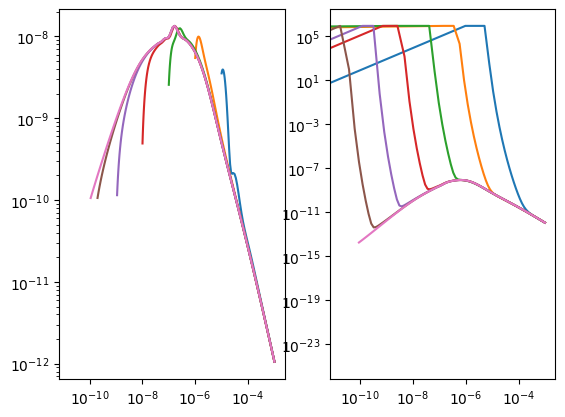

In [200]:
rho = torch.tensor([30., 50., 20.])*10.
thk = torch.tensor([30., 30.])

tx = Loop.square(100)
rx = Receiver(z=0.02)
t0 = np.geomspace(1e-9, 2e-3, 101)
t = np.concatenate([-t0[::-1], t0])
t = torch.from_numpy(t).to(torch.double)
filt = ButterworthFilter(5e5)

# wv = Waveform.example()


fig,ax = plt.subplots(1,2, sharex=True)

for i,deltat in enumerate(10.**(-torch.arange(5, 12))):
    print(deltat)
    fwr = ForwardLaplace6(tx, rx, t, wv) 
    fwr.delta_t = deltat
    fwr.t_eval = torch.logspace(-10, -3, 101).to(torch.double)+deltat
    dbdt = torch.clamp(fwr(rho, thk), 0, 1.) / c.mu0

    ax[0].loglog(fwr.t_eval,  dbdt, f'C{i}')
    ax[0].loglog(fwr.t_eval, -dbdt, f'C{i}--')

    fwr = ForwardLaplace6(tx, rx, t, wv, filterfunc=filt)
    fwr.delta_t = -deltat
    fwr.t_eval = torch.logspace(-10, -3, 101).to(torch.double)-deltat
    dbdt = torch.clamp(fwr(rho, thk), 0, 1.) / c.mu0

    ax[1].loglog(fwr.t_eval,  dbdt, f'C{i}')
    ax[1].loglog(fwr.t_eval, -dbdt, f'C{i}--')

# ax.set_xscale('symlog', linthresh=1e-7)
# ax.set_yscale('log')

# ax2 = ax.twinx()
# ax2.plot(wv.time, wv.amplitude, 'k-')

In [188]:

fwr1 = OnTimeForward(tx, rx, t, wv, filterfunc=filt)
dbdt1,hz1 = fwr1(rho, thk)


t = torch.from_numpy(t0)
fwr0 = Forward(tx, rx, t, waveform=wv)

dbdt0 = fwr0(rho, thk).squeeze()


/home/matt/repositories/anemone/src/anemone/experiment/experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


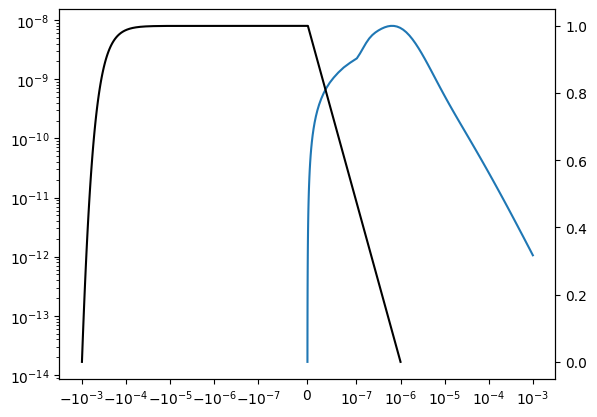

In [189]:
fig,ax = plt.subplots()

ax.plot(fwr.t_eval,  dbdt)
ax.plot(fwr.t_eval, -dbdt, 'C0--')
# ax.plot(fwr0.times, dbdt0, 'C1')
# ax.plot(fwr0.times,-dbdt0, 'C1--')

ax.set_xscale('symlog', linthresh=1e-7)
ax.set_yscale('log')

ax2 = ax.twinx()
ax2.plot(wv.time, wv.amplitude, 'k-')

/home/matt/environments/anemone/lib/python3.12/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/matt/environments/anemone/lib/python3.12/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


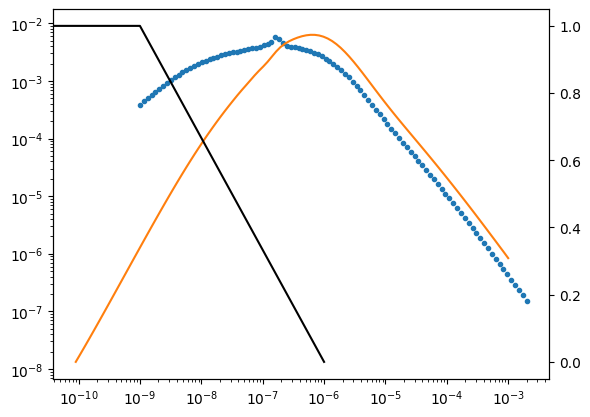

In [190]:
fig,ax = plt.subplots()

ax.loglog(fwr.times,  hz1, 'C0.')
ax.loglog(fwr.times, -hz1, 'C0.--')

ax.loglog(fwr.t_eval,  dbdt/c.mu0, 'C1')
ax.loglog(fwr.t_eval, -dbdt/c.mu0, 'C1--')

# ax.set_ylim(1e-2, 3e-2)


# ax.set_xscale('symlog', linthresh=1e-7)
# ax.set_yscale('log')

ax2 = ax.twinx()
ax2.plot(wv.time, wv.amplitude, 'k-')

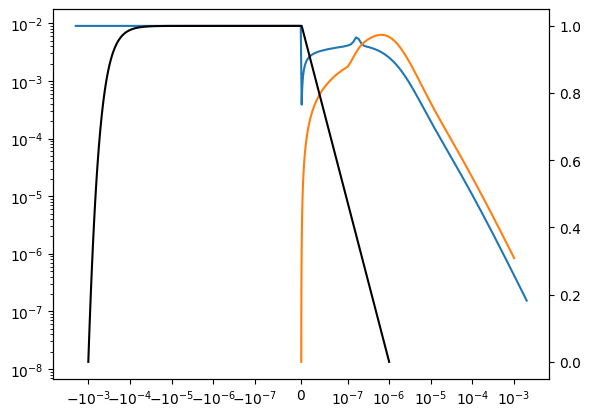

In [192]:
fig,ax = plt.subplots()

ax.plot(fwr.times,  hz1, 'C0')
ax.plot(fwr.times, -hz1, 'C0--')

ax.plot(fwr.t_eval,  dbdt/c.mu0, 'C1')
ax.plot(fwr.t_eval, -dbdt/c.mu0, 'C1--')

# ax.set_ylim(0.5e-2, 3e-2)


ax.set_xscale('symlog', linthresh=1e-7)
ax.set_yscale('log')

ax2 = ax.twinx()
ax2.plot(wv.time, wv.amplitude, 'k-')